# Cuaderno 04: Diseño, Evaluación y Entrenamiento de Modelos de ML
Este cuaderno cubre desde la formulación del problema y baselines hasta la evaluación en prueba, interpretación, ablación y prueba de humo del modelo guardado.

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print("Directorio del proyecto:", PROJECT_ROOT)

Directorio del proyecto: /Users/beto/Documents/PRUEBAS/TITANIC/proyecto_ciencia_de_datos


In [ ]:
%pip install -e "../.[dev]"

In [13]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    brier_score_loss,
    classification_report,
    f1_score,
    precision_recall_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    learning_curve,
)

from flows.common.paths import BRONZE, BRONZE_UNLABELED_NAME, MODELS

ml = importlib.import_module("flows.05_ml_models")
de = importlib.import_module("flows.01_data_engineering")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.figsize'] = (8, 5)


## Parte 10 — Del análisis a la predicción: formulación del problema
### Paso 39 y 40: Carga del dataset y auditoría de variables

In [14]:
X, y = ml.load_dataset()
print("Dimensiones de X:", X.shape)
print("Tasa de supervivencia global:", round(float(y.mean()), 4))
print("Columnas en X candidatas:", list(X.columns))
X.head()


Dimensiones de X: (891, 12)
Tasa de supervivencia global: 0.3838
Columnas en X candidatas: ['Age', 'SibSp', 'Parch', 'Fare', 'Familia', 'Pclass', 'Sex', 'Embarked', 'TTitulo', 'Alone', 'HasCabin', 'TCabin']


,Age,SibSp,Parch,Fare,Familia,Pclass,Sex,Embarked,TTitulo,Alone,HasCabin,TCabin
0,22.0,1,0,7.2500,1,3,male,S,Mr,with Family,0,X
1,38.0,1,0,71.2833,1,1,female,C,Mrs,with Family,1,C
2,26.0,0,0,7.9250,0,3,female,S,Miss,Alone,0,X
3,35.0,1,0,53.1000,1,1,female,S,Mrs,with Family,1,C
4,35.0,0,0,8.0500,0,3,male,S,Mr,Alone,0,X


### Paso 41: División estratificada entrenamiento / prueba
Se divide una única vez. `X_test` no se toca hasta la evaluación final en la Parte 16.

In [15]:
X_train, X_test, y_train, y_test = ml.split(X, y)
print(f"Entrenamiento: {X_train.shape[0]} filas, tasa de supervivencia: {y_train.mean():.4f}")
print(f"Prueba: {X_test.shape[0]} filas, tasa de supervivencia: {y_test.mean():.4f}")


Entrenamiento: 712 filas, tasa de supervivencia: 0.3834
Prueba: 179 filas, tasa de supervivencia: 0.3855


### Paso 42: Baselines a superar

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Baseline 1: Dummy más frecuente
dummy_pipe = ml.build_pipeline(DummyClassifier(strategy='most_frequent'))
dummy_preds = cross_val_predict(dummy_pipe, X_train, y_train, cv=cv)
print("--- Baseline Ingenuo (Most Frequent) ---")
print(classification_report(y_train, dummy_preds, zero_division=0))

# Baseline 2: Regla de género (mujeres = 1, hombres = 0)
gender_preds = (X_train['Sex'] == 'female').astype(int)
print("--- Baseline Heurístico (Regla de Género) ---")
print(classification_report(y_train, gender_preds))


--- Baseline Ingenuo (Most Frequent) ---
              precision    recall  f1-score   support

           0       0.62      1.00      0.76       439
           1       0.00      0.00      0.00       273

    accuracy                           0.62       712
   macro avg       0.31      0.50      0.38       712
weighted avg       0.38      0.62      0.47       712

--- Baseline Heurístico (Regla de Género) ---
              precision    recall  f1-score   support

           0       0.81      0.85      0.83       439
           1       0.74      0.69      0.71       273

    accuracy                           0.79       712
   macro avg       0.78      0.77      0.77       712
weighted avg       0.79      0.79      0.79       712



## Parte 11 — Preprocesamiento reproducible con `Pipeline`
### Paso 43: Demostración de Fuga de Datos (Data Leakage)

In [17]:
media_mujeres_global = X.loc[X['Sex'] == 'female', 'Age'].mean()
media_mujeres_train = X_train.loc[X_train['Sex'] == 'female', 'Age'].mean()

print(f"Edad media mujeres (todos los datos X): {media_mujeres_global:.4f}")
print(f"Edad media mujeres (solo X_train):      {media_mujeres_train:.4f}")
print(f"Diferencia: {abs(media_mujeres_global - media_mujeres_train):.4f} años")


Edad media mujeres (todos los datos X): 27.9157
Edad media mujeres (solo X_train):      28.1834
Diferencia: 0.2677 años


### Paso 44 a 46: Verificación del Pipeline y One-Hot Encoding

In [18]:
pipe_check = ml.build_pipeline(DummyClassifier())
prep_transformer = pipe_check[:-1].fit(X_train)
Z_test = prep_transformer.transform(X_test)

print(f"¿Existen NaN en la matriz preprocesada? {np.isnan(Z_test).any()}")
print(f"Número de columnas tras preprocesamiento: {Z_test.shape[1]}")
feature_names = prep_transformer['prep'].get_feature_names_out()
print("Nombres de variables codificadas:")
print(feature_names)


¿Existen NaN en la matriz preprocesada? False
Número de columnas tras preprocesamiento: 19
Nombres de variables codificadas:
['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'num__Familia'
 'cat__Pclass_1' 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female'
 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S'
 'cat__TTitulo_Miss' 'cat__TTitulo_Mr' 'cat__TTitulo_Mrs'
 'cat__TTitulo_Otro' 'cat__Alone_Alone' 'cat__Alone_with Family']


## Parte 12 — Modelos candidatos y validación cruzada
### Pasos 47 a 50: Comparación de modelos candidatos

In [19]:
cv_summary = ml.cross_validate_candidates(X_train, y_train)
display(cv_summary)


2026-11-08 01:31:40,441 | INFO | flows.05_ml_models | CV dummy - ROC-AUC: 0.5000 (+/- 0.0000)


/Users/beto/Documents/PRUEBAS/TITANIC/proyecto_ciencia_de_datos/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/beto/Documents/PRUEBAS/TITANIC/proyecto_ciencia_de_datos/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/beto/Documents/PRUEBAS/TITANIC/proyecto_ciencia_de_datos/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_divisio

2026-11-08 01:31:40,661 | INFO | flows.05_ml_models | CV logreg - ROC-AUC: 0.8585 (+/- 0.0236)
2026-11-08 01:31:40,853 | INFO | flows.05_ml_models | CV tree - ROC-AUC: 0.8468 (+/- 0.0260)
2026-11-08 01:31:42,928 | INFO | flows.05_ml_models | CV forest - ROC-AUC: 0.8653 (+/- 0.0161)
2026-11-08 01:31:45,100 | INFO | flows.05_ml_models | CV hgb - ROC-AUC: 0.8867 (+/- 0.0194)
2026-11-08 01:31:45,377 | INFO | flows.05_ml_models | CV knn - ROC-AUC: 0.8408 (+/- 0.0168)


,model,test_roc_auc_mean,test_roc_auc_std,train_roc_auc_mean,test_accuracy_mean,test_f1_mean,test_precision_mean,test_recall_mean,auc_overfit_gap
0,hgb,0.886742,0.019383,0.993573,0.820230,0.755340,0.795680,0.721549,0.106831
1,forest,0.865265,0.016125,0.998415,0.803398,0.735842,0.759134,0.714276,0.133151
2,logreg,0.858472,0.023599,0.864676,0.792140,0.719913,0.747941,0.696027,0.006203
3,tree,0.846757,0.025953,0.893225,0.804738,0.718860,0.818116,0.652121,0.046468
4,knn,0.840785,0.016818,0.928262,0.786536,0.710101,0.746657,0.681279,0.087477
5,dummy,0.500000,0.000000,0.500000,0.616576,0.000000,0.000000,0.000000,0.000000


### Gráfico de desempeño y sobreajuste por modelo

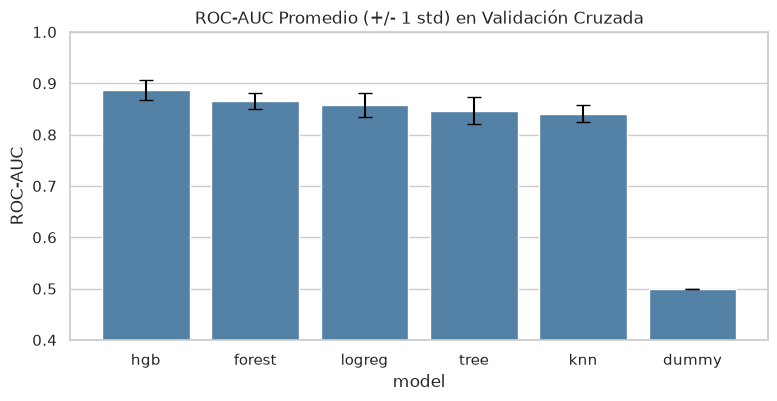

Brecha de sobreajuste (Train AUC - Test AUC):


,model,train_roc_auc_mean,test_roc_auc_mean,auc_overfit_gap
0,hgb,0.993573,0.886742,0.106831
1,forest,0.998418,0.865719,0.132699
2,logreg,0.864676,0.858452,0.006224
3,tree,0.893225,0.846757,0.046468
4,knn,0.928104,0.840764,0.087340
5,dummy,0.500000,0.500000,0.000000


In [8]:
plt.figure(figsize=(9, 4))
sns.barplot(data=cv_summary, x='model', y='test_roc_auc_mean', color='steelblue')
plt.errorbar(x=range(len(cv_summary)), y=cv_summary['test_roc_auc_mean'],
             yerr=cv_summary['test_roc_auc_std'], fmt='none', c='black', capsize=5)
plt.title('ROC-AUC Promedio (+/- 1 std) en Validación Cruzada')
plt.ylabel('ROC-AUC')
plt.ylim(0.4, 1.0)
plt.show()

print("Brecha de sobreajuste (Train AUC - Test AUC):")
display(cv_summary[['model', 'train_roc_auc_mean', 'test_roc_auc_mean', 'auc_overfit_gap']])


## Parte 13 — Evaluación en profundidad de los finalistas
### Paso 51 y 52: Predicciones fuera de muestra, Matriz de Confusión y Curvas ROC / PR

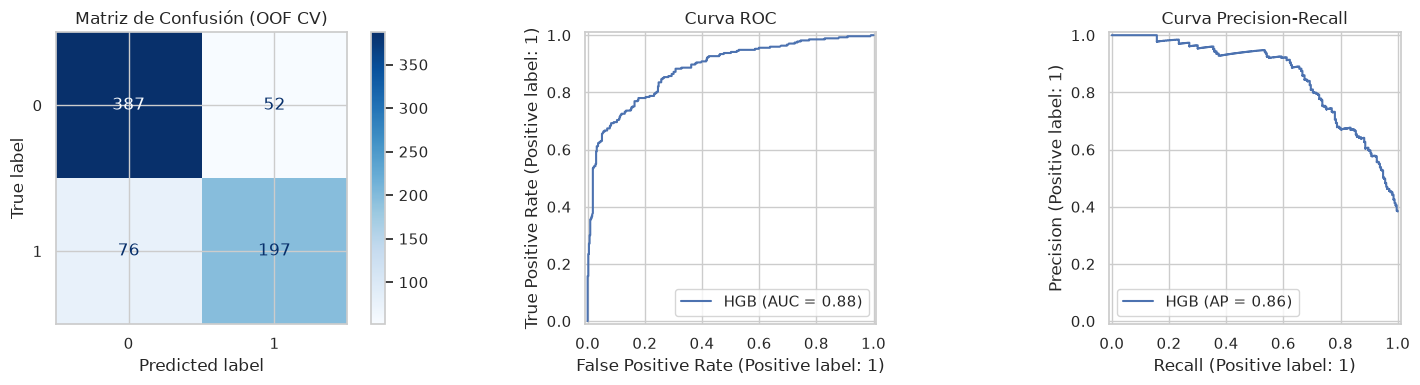

              precision    recall  f1-score   support

           0       0.84      0.88      0.86       439
           1       0.79      0.72      0.75       273

    accuracy                           0.82       712
   macro avg       0.81      0.80      0.81       712
weighted avg       0.82      0.82      0.82       712



In [9]:
candidates = ml.get_candidates(42)
pipe_final = ml.build_pipeline(candidates['hgb'])

proba_cv = cross_val_predict(pipe_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
pred_cv = (proba_cv >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(y_train, pred_cv, ax=axes[0], cmap='Blues')
axes[0].set_title('Matriz de Confusión (OOF CV)')

RocCurveDisplay.from_predictions(y_train, proba_cv, ax=axes[1], name='HGB')
axes[1].set_title('Curva ROC')

PrecisionRecallDisplay.from_predictions(y_train, proba_cv, ax=axes[2], name='HGB')
axes[2].set_title('Curva Precision-Recall')

plt.tight_layout()
plt.show()

print(classification_report(y_train, pred_cv))


### Paso 53: Calibración y elección del umbral

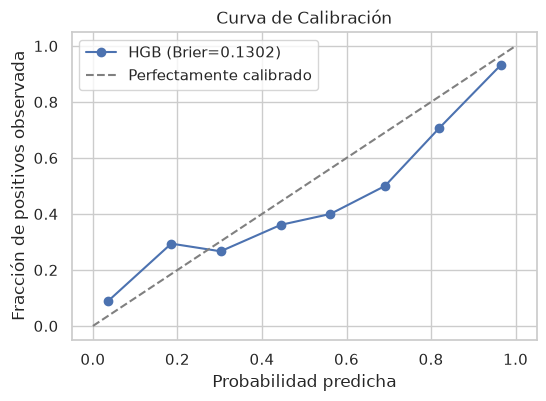

Brier score: 0.1302 (azar = 0.25, perfecto = 0)
Umbral que maximiza F1 en validación: 0.6086 (F1 máx = 0.7590)
F1 con umbral estándar 0.5: 0.7548


In [10]:
prob_true, prob_pred = calibration_curve(y_train, proba_cv, n_bins=8)
brier = brier_score_loss(y_train, proba_cv)

plt.figure(figsize=(6, 4))
plt.plot(prob_pred, prob_true, marker='o', label=f'HGB (Brier={brier:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente calibrado')
plt.xlabel('Probabilidad predicha')
plt.ylabel('Fracción de positivos observada')
plt.title('Curva de Calibración')
plt.legend()
plt.show()

precisions, recalls, thresholds = precision_recall_curve(y_train, proba_cv)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[min(best_idx, len(thresholds) - 1)]

print(f"Brier score: {brier:.4f} (azar = 0.25, perfecto = 0)")
print(f"Umbral que maximiza F1 en validación: {best_threshold:.4f} (F1 máx = {f1_scores[best_idx]:.4f})")
print(f"F1 con umbral estándar 0.5: {f1_score(y_train, pred_cv):.4f}")


### Paso 54: Análisis de errores por subgrupos

In [11]:
df_errors = X_train.copy()
df_errors['y_true'] = y_train
df_errors['proba'] = proba_cv
df_errors['pred'] = pred_cv
df_errors['error'] = df_errors['y_true'] != df_errors['pred']

print("Tasa de error por Sexo:")
display(df_errors.groupby('Sex')['error'].agg(['mean', 'count']))

print("\nTasa de error por Clase:")
display(df_errors.groupby('Pclass')['error'].agg(['mean', 'count']))

print("\n10 errores concretos con alta confianza:")
high_conf_errors = df_errors[df_errors['error']].sort_values(
    by='proba', key=lambda p: np.abs(p - 0.5), ascending=False
).head(10)
display(high_conf_errors[['Sex', 'Pclass', 'Age', 'Fare', 'TTitulo', 'y_true', 'proba', 'pred']])


Tasa de error por Sexo:


,mean,count
Sex,,
female,0.193676,253
male,0.172113,459



Tasa de error por Clase:


,mean,count
Pclass,,
1,0.210526,171
2,0.086667,150
3,0.202046,391



10 errores concretos con alta confianza:


,Sex,Pclass,Age,Fare,TTitulo,y_true,proba,pred
127,male,3,24.0,7.1417,Mr,1,0.000522,0
821,male,3,27.0,8.6625,Mr,1,0.002760,0
226,male,2,19.0,10.5000,Mr,1,0.004259,0
498,female,1,25.0,151.5500,Mrs,0,0.992951,1
709,male,3,NaN,15.2458,Mr,1,0.007888,0
177,female,1,50.0,28.7125,Miss,0,0.987446,1
569,male,3,32.0,7.8542,Mr,1,0.012772,0
510,male,3,29.0,7.7500,Mr,1,0.014535,0
391,male,3,21.0,7.7958,Mr,1,0.015617,0
854,female,2,44.0,26.0000,Mrs,0,0.982590,1


### Paso 55: Curva de aprendizaje

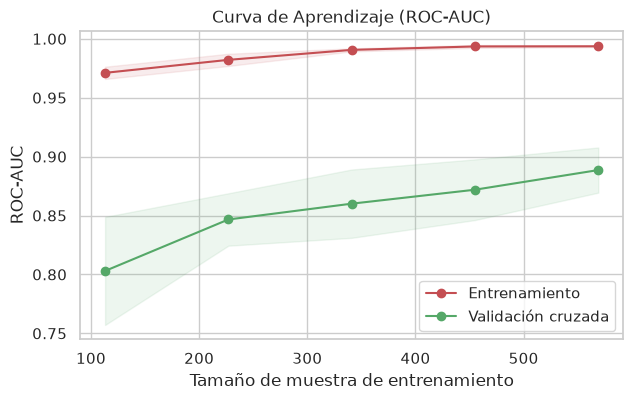

In [12]:
train_sizes, train_scores, val_scores = learning_curve(
    pipe_final, X_train, y_train, cv=cv, train_sizes=np.linspace(0.2, 1.0, 5), scoring='roc_auc'
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(7, 4))
plt.plot(train_sizes, train_mean, 'o-', color='r', label='Entrenamiento')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
plt.plot(train_sizes, val_mean, 'o-', color='g', label='Validación cruzada')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='g')
plt.title('Curva de Aprendizaje (ROC-AUC)')
plt.xlabel('Tamaño de muestra de entrenamiento')
plt.ylabel('ROC-AUC')
plt.legend()
plt.show()


## Parte 14 — Ajuste de hiperparámetros
### Pasos 56 a 58: Búsqueda con GridSearchCV

In [13]:
param_grids = ml.get_param_grids()
grid_hgb = GridSearchCV(
    pipe_final, param_grids['hgb'], cv=cv, scoring='roc_auc', n_jobs=-1, refit=True
)
grid_hgb.fit(X_train, y_train)

print(f"Mejor ROC-AUC en CV: {grid_hgb.best_score_:.4f}")
print("Mejores parámetros encontrados:")
print(grid_hgb.best_params_)


Mejor ROC-AUC en CV: 0.8925
Mejores parámetros encontrados:
{'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__max_iter': 200}


## Parte 15 — Interpretación y ablación de variables
### Paso 59: Coeficientes de Regresión Logística y Odds Ratios

In [14]:
pipe_lr = ml.build_pipeline(candidates['logreg']).fit(X_train, y_train)
feature_names_out = pipe_lr['prep'].get_feature_names_out()
coefs = pipe_lr['model'].coef_[0]

df_coefs = pd.DataFrame({
    'Feature': feature_names_out,
    'Coeficiente': coefs,
    'Odds_Ratio': np.exp(coefs)
}).sort_values(by='Coeficiente', ascending=False).reset_index(drop=True)

display(df_coefs)


,Feature,Coeficiente,Odds_Ratio
0,cat__Pclass_1,1.165170,3.206467
1,cat__Sex_female,0.937788,2.554326
2,cat__TTitulo_Mrs,0.729454,2.073948
3,cat__Embarked_Q,0.372090,1.450764
4,cat__Alone_with Family,0.228081,1.256187
5,num__Fare,0.119247,1.126648
6,cat__Embarked_C,0.004007,1.004015
7,cat__Pclass_2,0.000015,1.000015
8,cat__TTitulo_Otro,-0.054311,0.947137
9,cat__TTitulo_Miss,-0.086285,0.917333


### Paso 60: Importancia por permutación

/tmp/ipykernel_1869/1099189680.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_perm, x='Importance_Mean', y='Feature', palette='Blues_r')


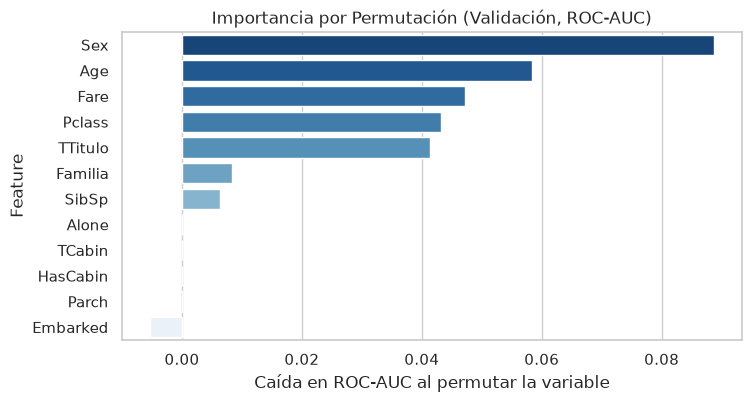

In [15]:
X_tr_sub, X_val_sub, y_tr_sub, y_val_sub = ml.split(X_train, y_train, test_size=0.25, random_state=42)
pipe_fit_sub = ml.build_pipeline(candidates['hgb']).fit(X_tr_sub, y_tr_sub)

perm_imp = permutation_importance(
    pipe_fit_sub, X_val_sub, y_val_sub, scoring='roc_auc', n_repeats=30, random_state=42
)

df_perm = pd.DataFrame({
    'Feature': X_val_sub.columns,
    'Importance_Mean': perm_imp.importances_mean,
    'Importance_Std': perm_imp.importances_std,
}).sort_values(by='Importance_Mean', ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))
sns.barplot(data=df_perm, x='Importance_Mean', y='Feature', palette='Blues_r')
plt.title('Importancia por Permutación (Validación, ROC-AUC)')
plt.xlabel('Caída en ROC-AUC al permutar la variable')
plt.show()


### Paso 61: Estudio de Ablación

In [16]:
# Configuraciones de variables
configs = {
    "A) Base": (ml.NUM_FEATURES, ml.CAT_FEATURES),
    "B) Base + Cabina": (ml.NUM_FEATURES + ml.CABIN_NUM, ml.CAT_FEATURES + ml.CABIN_CAT),
    "C) Sin Titulo": (ml.NUM_FEATURES, [c for c in ml.CAT_FEATURES if c != "TTitulo"]),
    "D) Sin Sexo": (ml.NUM_FEATURES, [c for c in ml.CAT_FEATURES if c != "Sex"]),
}

ablation_results = []
for name, (num_f, cat_f) in configs.items():
    pipe_ab = ml.build_pipeline(candidates['hgb'], num_features=num_f, cat_features=cat_f)
    res_ab = ml.cross_validate(pipe_ab, X_train, y_train, cv=cv, scoring='roc_auc')
    ablation_results.append({
        "Configuracion": name,
        "ROC_AUC_Mean": float(res_ab['test_score'].mean()),
        "ROC_AUC_Std": float(res_ab['test_score'].std()),
    })

df_ablation = pd.DataFrame(ablation_results)
df_ablation['Delta_vs_Base'] = df_ablation['ROC_AUC_Mean'] - df_ablation.loc[0, 'ROC_AUC_Mean']
display(df_ablation)


,Configuracion,ROC_AUC_Mean,ROC_AUC_Std,Delta_vs_Base
0,A) Base,0.886742,0.019383,0.000000
1,B) Base + Cabina,0.887053,0.021155,0.000310
2,C) Sin Titulo,0.877169,0.016915,-0.009573
3,D) Sin Sexo,0.883450,0.019815,-0.003292


## Parte 16 — Evaluación final honesta sobre el conjunto de prueba
### Pasos 62 y 63: Evaluación única con incertidumbre bootstrap

In [17]:
# Ajuste del modelo elegido sobre todo X_train
num_final = ml.NUM_FEATURES + (ml.CABIN_NUM if ml.USE_CABIN_FEATURES else [])
cat_final = ml.CAT_FEATURES + (ml.CABIN_CAT if ml.USE_CABIN_FEATURES else [])

pipe_eval_test = ml.build_pipeline(candidates[ml.FINAL_ESTIMATOR], num_features=num_final, cat_features=cat_final)
pipe_eval_test.set_params(**ml.FINAL_PARAMS)
pipe_eval_test.fit(X_train, y_train)

test_metrics = ml.evaluate_on_test(pipe_eval_test, X_test, y_test, threshold=ml.THRESHOLD)
print("--- Métricas en el Conjunto de Prueba ---")
print(test_metrics)

# Bootstrap 95% CI (1000 remuestreos)
proba_test = pipe_eval_test.predict_proba(X_test)[:, 1]
rng = np.random.default_rng(42)
n_test = len(y_test)
boot_aucs, boot_accs = [], []

for _ in range(1000):
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_b = y_test.iloc[idx]
    if len(np.unique(y_b)) < 2:
        continue
    p_b = proba_test[idx]
    boot_aucs.append(ml.roc_auc_score(y_b, p_b))
    boot_accs.append(ml.accuracy_score(y_b, (p_b >= ml.THRESHOLD).astype(int)))

ci_auc = (np.percentile(boot_aucs, 2.5), np.percentile(boot_aucs, 97.5))
ci_acc = (np.percentile(boot_accs, 2.5), np.percentile(boot_accs, 97.5))

print(f"ROC-AUC Test: {test_metrics['roc_auc']:.4f} (IC 95%: [{ci_auc[0]:.4f}, {ci_auc[1]:.4f}])")
print(f"Accuracy Test: {test_metrics['accuracy']:.4f} (IC 95%: [{ci_acc[0]:.4f}, {ci_acc[1]:.4f}])")


--- Métricas en el Conjunto de Prueba ---
{'accuracy': 0.7989, 'f1': 0.7143, 'roc_auc': 0.8277, 'threshold': 0.5, 'n_test': 179}
ROC-AUC Test: 0.8277 (IC 95%: [0.7555, 0.8927])
Accuracy Test: 0.7989 (IC 95%: [0.7374, 0.8547])


## Parte 17 — Modelo definitivo y prueba de humo
### Paso 65 a 69: Carga del modelo guardado y prueba con datos sin etiqueta

In [18]:
# Cargar el modelo guardado desde disco
pipe_loaded, metadata_loaded = ml.load_model(MODELS / f"{ml.MODEL_NAME}.joblib")
print("Modelo cargado exitosamente. Metadatos registrados:")
print(f"Estimador: {metadata_loaded['estimator']}, Python: {metadata_loaded['python_version']}, Sklearn: {metadata_loaded['sklearn_version']}")

# Prueba de humo con datos sin etiqueta (titanic_unlabeled.csv)
df_unlabeled = pd.read_csv(BRONZE / BRONZE_UNLABELED_NAME)
print(f"Datos sin etiqueta leídos: {df_unlabeled.shape[0]} filas.")

# Preprocesar con las transformaciones deterministas de Silver
unlabeled_processed = de.build_silver(df_unlabeled)
X_unlabeled = unlabeled_processed[ml.CANDIDATE_COLUMNS].copy()
X_unlabeled['Age'] = unlabeled_processed['AgeOriginal']

predictions_new = ml.predict(pipe_loaded, X_unlabeled, threshold=ml.THRESHOLD)
print("Predicciones para los pasajeros nuevos:")
print(f"¿Hay valores NaN en las predicciones? {predictions_new.isna().any().to_dict()}")
print(f"Distribución de supervivientes predichos:\n{predictions_new['pred'].value_counts(normalize=True).round(3)}")
display(predictions_new.head(10))


Modelo cargado exitosamente. Metadatos registrados:
Estimador: hgb, Python: 3.12.3, Sklearn: 1.9.1
Datos sin etiqueta leídos: 418 filas.
2026-11-07 13:11:12,074 | INFO | flows.01_data_engineering | Desviación estándar de Age antes de imputar: 14.18, después: 12.63
Predicciones para los pasajeros nuevos:
¿Hay valores NaN en las predicciones? {'proba_survive': False, 'pred': False}
Distribución de supervivientes predichos:
pred
0    0.66
1    0.34
Name: proportion, dtype: float64


,proba_survive,pred
0,0.067174,0
1,0.298390,0
2,0.080368,0
3,0.129573,0
4,0.495776,0
5,0.107916,0
6,0.669892,1
7,0.115534,0
8,0.872236,1
9,0.112392,0
